### Polynomail LinearRegression
#### Use if your data is curved

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

### Creating a dtaset 

In [2]:
x = 6*np.random.rand(200,1) - 3
y = 0.8 * x**2 + 0.9 * x + 2+ np.random.randn(200,1)

### Visualizing the data

Text(0, 0.5, 'y')

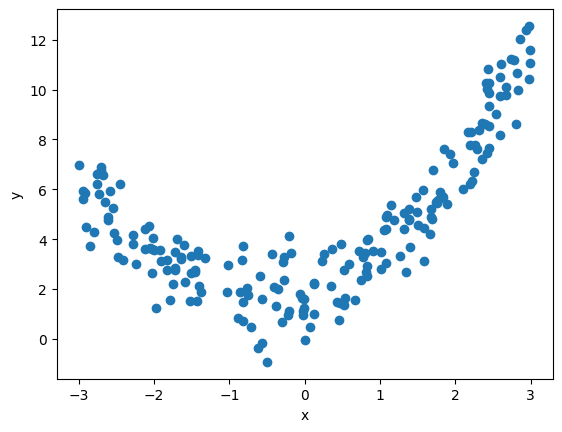

In [3]:
plt.scatter(x,y)
plt.xlabel("x")
plt.ylabel("y")

### Spliting data

In [4]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=11)

### Applying polynomial features to the training data

In [56]:
poly_features = PolynomialFeatures(degree=3, include_bias=False)
x_train_poly = poly_features.fit_transform(x_train)
x_test_poly = poly_features.transform(x_test)

In [57]:
print(x_train[0])
print(x_train_poly[0])

[0.53613198]
[0.53613198 0.2874375  0.15410443]


In [58]:
model = LinearRegression()
model.fit(x_train_poly,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [59]:
pred = model.predict(x_test_poly)

In [60]:
print('r2_score:',r2_score(y_test,pred))

r2_score: 0.8818021857252135


### Ploting regression line

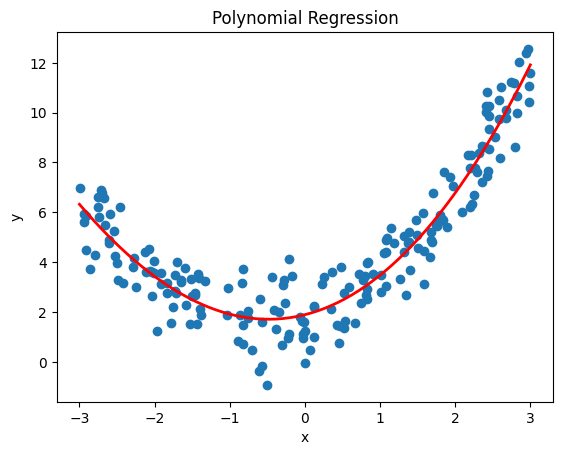

In [61]:
x_ =np.linspace(-3,3,200).reshape(200,1)
x_poly = poly_features.transform(x_)
y_ = model.predict(x_poly)

plt.scatter(x,y)
plt.plot(x_, y_, color='red', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression')
plt.show()

### Now without Polynomail featuers

In [62]:
model1 = LinearRegression()
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [63]:
predictions = model1.predict(x_test)

In [64]:
print('r2_score:',r2_score(y_test,predictions))
### its r2_score is less than polynomial regression because linear regression is not able to capture the non-linear relationship between x and y.

r2_score: 0.3289334233369593


### ploting the linear regression model

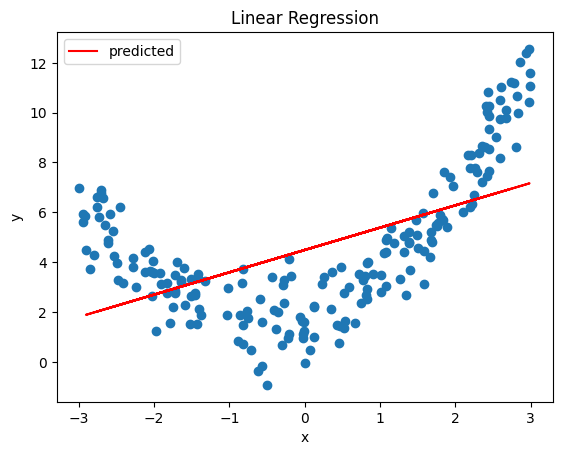

In [65]:
plt.scatter(x,y)
plt.plot(x_test,predictions,color='r',label='predicted')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Regression')
plt.legend()
plt.show()